# The radiometry of images: the camera equation, cos⁴ and how bright an image is

A lens cannot make an object look brighter than it is: the radiance in
the image is at most that of the object (notebook 105, radiometry and photometry). What a lens does
set is how much of that radiance arrives at each point of the image, from
how wide a cone. This notebook follows the consequences, from the
exposure of a photograph to the view through a telescope:

1. the camera equation: the irradiance in the image of an extended
   object, $E' = \pi TL/(4N_w^2)$, checked with real rays through the
   double Gauss of notebook 90 (bokeh) at infinity and at close range, and the
   T-number,
2. the $\cos^4$ law of the falloff towards the corners, taken apart into
   its object side and image side factors with the real chief ray
   mapping,
3. how wide angle lenses beat $\cos^4$: a 28 mm f/2.8 retrofocus lens,
   designed for this notebook, whose entrance pupil grows towards the
   field,
4. point sources and extended sources: why a telescope shows more stars
   but never a brighter Moon, and how bright a microscope image is,
5. from luminance to electrons: the sunny 16 rule, the exposure at the
   sensor and the photons per pixel that set the noise.

The tools are `pyoptics.radiometry` (`camera_irradiance()`,
`working_f_number()`, `metered_exposure()`) and
`pyoptics.photography` (`double_gauss()`, `retrofocus()`,
`relative_illumination()` with `image_side=True`, `chief_ray_mapping()`).
Radiometric terms as defined in notebook 105 (radiometry and photometry); everything said in watts
holds in lumens.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import radiometry as rad
from pyoptics import photography as ph
from pyoptics import raytrace as rt
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(106)

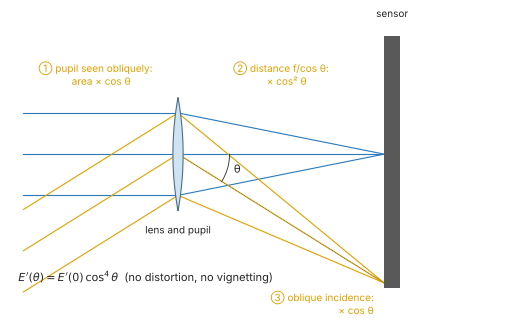

In [2]:
fig, ax = plt.subplots(figsize=(12, 4.6))
sketch.cos4_law(ax)
plt.show()

## 1. The camera equation

An extended Lambertian object of radiance $L$ sends light into the lens
from every point. By the brightness theorem the image has the radiance
$TL$ (times $(n'/n)^2$), filling the cone of the image space numerical
aperture $\sin\theta'$ in which the light arrives. Integrating the radiance
over that cone, as in section 1 of notebook 105 (radiometry and photometry), gives the irradiance on
the axis:

$$E' = \pi T L\sin^2\theta' = \frac{\pi T L}{4N_w^2},\qquad N_w = N\left(1 + \frac{|m|}{m_p}\right).$$

The second form needs two facts of lens design. At infinity, a lens that
obeys Abbe's sine condition has $\sin\theta' = D/2f = 1/(2N)$ exactly
(notebook 102, sine and Herschel conditions). At the magnification $m$ the cone narrows to the working
F-number $N_w$, which depends on the pupil magnification $m_p$ (exit
over entrance pupil diameter) as well, since the image distance from the
exit pupil is $f(m_p + |m|)$. This is the "bellows factor" of close-up
photography. The test traces the real marginal ray through the double
Gauss of notebook 90 (bokeh) to the on-axis image point and compares $\pi
\sin^2\theta'$ with $\pi/4N^2$.

In [3]:
def image_na(system):
    """sin of the angle of the real marginal ray at the on-axis image point (image space in air)."""
    b = system.trace(system.rays(0.0, 0.0, 1.0))
    d = b.directions[-1][0]
    return np.hypot(d[0], d[1])/np.linalg.norm(d)


print(" N     paraxial 1/(2N)   real marginal ray sin θ'   E'/L = π sin²θ'   π/(4N²)")
cam = {}
for N in (1.8, 2.8, 4.0, 8.0):
    lens = ph.double_gauss(N)
    s = image_na(lens)
    cam[N] = s
    print("{:4.1f}   {:.4f}            {:.4f}                     {:.4f}            {:.4f}".format(
        N, 1/(2*N), s, np.pi*s**2, np.pi/(4*N**2)))

 N     paraxial 1/(2N)   real marginal ray sin θ'   E'/L = π sin²θ'   π/(4N²)


 1.8   0.2778            0.2796                     0.2456            0.2424
 2.8   0.1786            0.1794                     0.1011            0.1002
 4.0   0.1250            0.1253                     0.0493            0.0491
 8.0   0.0625            0.0625                     0.0123            0.0123


At f/8 the two agree to four digits. Wide open at f/1.8 the real marginal
ray arrives at 0.2796 instead of 0.2778, so the image is 1.3 % brighter
than the formula says: the lens does not quite meet the sine condition
at its rim (it was designed for spot size). Next the lens, stopped down
to f/8, is focused closer.

In [4]:
# focusing closer: the working F-number
lens8 = ph.double_gauss(8.0)
p8 = lens8.paraxial()
m_p = p8.xp_radius/p8.ep_radius
print("pupil magnification m_p = {:.3f}".format(m_p))
dists = np.array([5000.0, 2000.0, 1000.0, 500.0, 300.0, 200.0, 150.0])
rows = []
for d in dists:
    S = rt.System(lens8.surfaces, lens8.stop_index, lens8.wavelength, object_distance=d,
                  object_height=1.0).at_paraxial_focus()
    pS = S.paraxial()
    m = pS.magnification
    rows.append((d, m, image_na(S), 1/(2*rad.working_f_number(8.0, m, m_p)), 1/(2*8.0*(1 + abs(m)))))
rows = np.array(rows)
print(" object (mm)   m        sin θ' traced   1/(2 N(1+|m|/m_p))   1/(2 N(1+|m|))")
for r in rows:
    print("{:8.0f}    {:7.4f}   {:.5f}         {:.5f}              {:.5f}".format(*r))

pupil magnification m_p = 1.232
 object (mm)   m        sin θ' traced   1/(2 N(1+|m|/m_p))   1/(2 N(1+|m|))
    5000    -0.0100   0.06204         0.06200              0.06188
    2000    -0.0252   0.06129         0.06125              0.06097
    1000    -0.0507   0.06008         0.06003              0.05949
     500    -0.1027   0.05774         0.05769              0.05668
     300    -0.1744   0.05481         0.05475              0.05322
     200    -0.2678   0.05140         0.05134              0.04930
     150    -0.3658   0.04826         0.04819              0.04576


The working F-number with the pupil magnification follows the traced
cone to 0.15 %. The textbook factor $(1 + |m|)$, which assumes
$m_p = 1$, darkens the image too much: at $m = -0.37$ it predicts 11 %
less light than there is. For macro lenses with very unequal pupils (a
retrofocus has $m_p \approx 2$, a telephoto $m_p < 1$) the difference is
larger.

What the camera equation calls $T$ is the transmittance of the lens.
Uncoated, every air–glass surface reflects about 4 to 7 %, and lens
makers quote a T-number $N/\sqrt T$, the F-number of a perfect lens that
gives the same image irradiance (cine lenses are marked in T-stops).

In [5]:
# transmittance: Fresnel losses at normal incidence, uncoated and with a 0.5 % coating per air-glass surface
n = np.asarray(lens8.n)
R_surf = ((n[1:] - n[:-1])/(n[1:] + n[:-1]))**2
air_glass = np.abs(n[1:] - n[:-1]) > 0.2
T_unc = np.prod(1 - R_surf)
T_coat = np.prod(np.where(air_glass, 1 - 0.005, 1 - R_surf))
print("{} air-glass surfaces; transmittance uncoated {:.3f}, coated {:.3f}".format(
    air_glass.sum(), T_unc, T_coat))
for N in (1.8, 2.8):
    print("f/{}: T-number uncoated T/{:.2f}, coated T/{:.2f}".format(N, N/np.sqrt(T_unc), N/np.sqrt(T_coat)))

8 air-glass surfaces; transmittance uncoated 0.583, coated 0.961
f/1.8: T-number uncoated T/2.36, coated T/1.84
f/2.8: T-number uncoated T/3.67, coated T/2.86


The eight air–glass surfaces of the double Gauss (two of its four
interfaces are cemented) would let only 58 % through without coatings,
and 96 % with a good antireflection coating of 0.5 % per surface. Wide
open the uncoated lens is a T/2.4 lens, the coated one T/1.84. Before
coatings were invented in the late 1930s, this loss, and the flare it
causes (notebook 92, flare and ghosts), limited lenses to four to six air–glass surfaces.

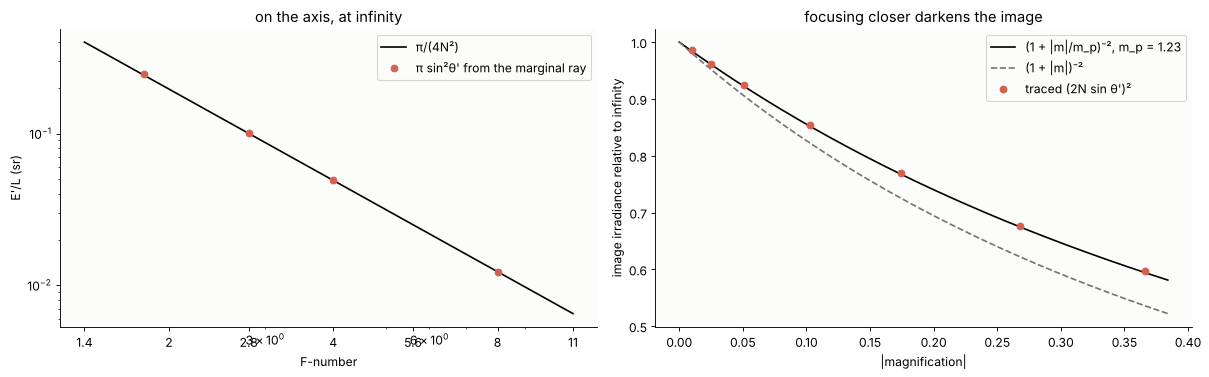

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
NN = np.linspace(1.4, 11, 200)
ax[0].loglog(NN, np.pi/(4*NN**2), color="k", label="π/(4N²)")
ax[0].loglog(list(cam), [np.pi*s**2 for s in cam.values()], "o", color=RED, label="π sin²θ' from the marginal ray")
ax[0].set_xlabel("F-number")
ax[0].set_ylabel("E'/L (sr)")
ax[0].set_title("on the axis, at infinity")
ax[0].set_xticks([1.4, 2, 2.8, 4, 5.6, 8, 11], ["1.4", "2", "2.8", "4", "5.6", "8", "11"])
ax[0].legend()
mm = np.linspace(0, 1.05*abs(rows[:, 1]).max(), 200)
ax[1].plot(mm, 1/(1 + mm/m_p)**2, color="k", label="(1 + |m|/m_p)⁻², m_p = {:.2f}".format(m_p))
ax[1].plot(mm, 1/(1 + mm)**2, "--", color=GREY, label="(1 + |m|)⁻²")
ax[1].plot(np.abs(rows[:, 1]), (rows[:, 2]*2*8.0)**2, "o", color=RED, label="traced (2N sin θ')²")
ax[1].set_xlabel("|magnification|")
ax[1].set_ylabel("image irradiance relative to infinity")
ax[1].set_title("focusing closer darkens the image")
ax[1].legend()
plt.show()

## 2. The cos⁴ law, taken apart

Off the axis the image gets darker. For an object at infinity, the light
from the solid angle $d\Omega$ around the field angle $\theta$ that
passes the lens is $L\,A_p(\theta)\,d\Omega$, where $A_p(\theta)$ is the
area of the entrance pupil projected onto the direction of the light (the
sketch at the top). It lands on the image area $dA'$ that the lens maps
$d\Omega$ to, so

$$\frac{E'(\theta)}{E'(0)} = \underbrace{\frac{A_p(\theta)}{A_p(0)}}_{\text{object side}}\;\underbrace{\frac{f^2\sin\theta\,d\theta}{h\,dh}}_{\text{image side}},$$

for the image height $h(\theta)$ of the chief ray. For a thin lens with a
round pupil, the projected pupil is $\cos\theta$, and a lens free of
distortion has $h = f\tan\theta$, so the image side factor is
$\cos^3\theta$. Together that is the $\cos^4$ law. Real lenses break both
assumptions. The pupil can grow or shrink with the field (pupil
aberration) and be cut by the rims of the lenses (vignetting, notebook
90, bokeh), and distortion moves image points and changes the image area per
solid angle.

`ph.relative_illumination()` measures the object side factor by tracing
rays from each field point through the whole aperture. With
`image_side=True` it multiplies by the image side factor from the real
chief ray mapping (`ph.chief_ray_mapping()`, central differences of the
chief ray height). The first check is an ideal lens, `rt.IdealLens`,
which has $h = f\tan\theta$ and no pupil aberration.

In [7]:
# first the check: an ideal lens (f tan θ mapping, no pupil aberration) must give exactly cos⁴
ideal = rt.System([rt.IdealLens(50.0, 50.0)], 0, ph.D_LINE, entrance_pupil_radius=50.0/16,
                  field_angle=np.deg2rad(40.0))
fields_id = np.deg2rad([10.0, 20.0, 30.0, 40.0])
RI_id = ph.relative_illumination(ideal, fields_id, 200000, rng, image_side=True)
print("ideal lens: RI", np.round(RI_id, 4), " cos⁴", np.round(np.cos(fields_id)**4, 4))

dg8 = ph.focus(ph.double_gauss(8.0))
dg18 = ph.focus(ph.double_gauss(1.8))
fields = np.deg2rad(np.linspace(0.0, 23.4, 14))[1:]
P8 = ph.relative_illumination(dg8, fields, 60000, rng)
RI8 = ph.relative_illumination(dg8, fields, 60000, rng, image_side=True)
RI18 = ph.relative_illumination(dg18, fields, 60000, rng, image_side=True)
h8, dh8 = ph.chief_ray_mapping(dg8, fields)
h0, dh0 = ph.chief_ray_mapping(dg8, [0.0])
area8 = np.sin(fields)*dh0[0]**2/(h8*dh8)
dist8 = h8/(dh0[0]*np.tan(fields)) - 1
print("double Gauss: chief ray distortion at 23.4°: {:.1f} %".format(100*dist8[-1]))
for f, p, a, r, r18 in zip(np.rad2deg(fields)[::3], P8[::3], area8[::3], RI8[::3], RI18[::3]):
    print("{:5.1f}°: pupil factor {:.3f} (cos θ {:.3f}), image side {:.3f} (cos³ θ {:.3f}), "
          "RI f/8 {:.3f}, f/1.8 {:.3f}, cos⁴ {:.3f}".format(
              f, p, np.cos(np.deg2rad(f)), a, np.cos(np.deg2rad(f))**3, r, r18, np.cos(np.deg2rad(f))**4))

ideal lens: RI [0.9387 0.7787 0.5636 0.3447]  cos⁴ [0.9406 0.7797 0.5625 0.3444]


double Gauss: chief ray distortion at 23.4°: -7.7 %
  1.8°: pupil factor 0.996 (cos θ 1.000), image side 1.000 (cos³ θ 0.999), RI f/8 0.995, f/1.8 1.005, cos⁴ 0.998
  7.2°: pupil factor 0.990 (cos θ 0.992), image side 1.001 (cos³ θ 0.977), RI f/8 0.992, f/1.8 0.988, cos⁴ 0.969
 12.6°: pupil factor 0.969 (cos θ 0.976), image side 1.008 (cos³ θ 0.929), RI f/8 0.974, f/1.8 0.861, cos⁴ 0.907
 18.0°: pupil factor 0.932 (cos θ 0.951), image side 1.032 (cos³ θ 0.860), RI f/8 0.958, f/1.8 0.625, cos⁴ 0.818
 23.4°: pupil factor 0.878 (cos θ 0.918), image side 1.099 (cos³ θ 0.773), RI f/8 0.969, f/1.8 0.362, cos⁴ 0.709


The ideal lens follows $\cos^4$ to the Monte Carlo noise of the pupil
sampling (0.3 %). The double Gauss does not. Its pupil seen from the
field shrinks a little faster than $\cos\theta$ (0.88 against 0.92 in the
corner at 23.4°). But its image side factor is not $\cos^3$ at all: this
design was optimized for sharpness only, and its chief ray lands 7.7 %
inside $f\tan\theta$ in the corner (barrel distortion, far more than the
1 to 2 % of commercial lenses of the type). Barrel distortion squeezes
the corners of the image into a smaller area, which concentrates the
light. The two together give 0.96 in the corner at f/8 instead of the
0.71 of $\cos^4$. Wide open at f/1.8 the cat's eye of notebook 90 (bokeh) cuts the
corner to 0.36. Vignetting, not $\cos^4$, darkens the corners of fast
normal lenses.

## 3. Beating cos⁴: the retrofocus lens

A wide angle lens for a reflex camera must leave room for the mirror:
its back focal length has to be longer than its focal length. The
retrofocus (inverted telephoto) layout does this with a negative front
group ahead of a positive rear group. The 28 mm f/2.8 lens of
`ph.retrofocus()` was designed for this notebook with
`lens_optimization.LensOptimizer`: a negative front element, a positive
flint, the stop, and a triplet-like rear group, 100 mm from the first
vertex to the image with a back focal length of 39 mm, over ±37.7° (the
corner of a 36 × 24 mm frame), with the distortion held below a few
percent.

The negative front group does more than make room. Seen from an oblique
field, it magnifies the stop more than from the axis, so the entrance
pupil grows and turns towards the field. This pupil aberration is the
"Slyusarev effect" (Slyusarev, 1941), and it is what lets wide angle
lenses beat $\cos^4$.

In [8]:
rf = ph.focus(ph.retrofocus(2.8))
prf = rf.paraxial()
print("retrofocus: efl {:.2f} mm, f/{:.2f}, back focal length {:.1f} mm, total length {:.1f} mm".format(
    prf.efl, prf.f_number, prf.bfl, rf.vertex_z[-1] + rf.surfaces[-1].thickness))
print("pupil magnification {:.2f}; entrance pupil {:.1f} mm behind the first vertex".format(
    prf.xp_radius/prf.ep_radius, prf.ep_z))
fields_rf = np.deg2rad(np.linspace(0.0, np.rad2deg(rf.max_field), 15))[1:]
P_rf = ph.relative_illumination(rf, fields_rf, 60000, rng)
RI_rf = ph.relative_illumination(rf, fields_rf, 60000, rng, image_side=True)
h_rf, dh_rf = ph.chief_ray_mapping(rf, fields_rf)
hrf0, dhrf0 = ph.chief_ray_mapping(rf, [0.0])
area_rf = np.sin(fields_rf)*dhrf0[0]**2/(h_rf*dh_rf)
dist_rf = h_rf/(dhrf0[0]*np.tan(fields_rf)) - 1
for f, p, a, r, d in zip(np.rad2deg(fields_rf)[::2], P_rf[::2], area_rf[::2], RI_rf[::2], dist_rf[::2]):
    c = np.cos(np.deg2rad(f))
    print("{:5.1f}°: pupil factor {:.3f} (cos θ {:.3f}), image side {:.3f} (cos³ {:.3f}), distortion {:+.1f} %, "
          "RI {:.3f}, cos⁴ {:.3f}".format(f, p, c, a, c**3, 100*d, r, c**4))

retrofocus: efl 28.00 mm, f/2.80, back focal length 39.1 mm, total length 99.9 mm
pupil magnification 2.34; entrance pupil 21.9 mm behind the first vertex


  2.7°: pupil factor 1.001 (cos θ 0.999), image side 1.000 (cos³ 0.997), distortion -0.1 %, RI 0.997, cos⁴ 0.996
  8.1°: pupil factor 1.006 (cos θ 0.990), image side 0.997 (cos³ 0.971), distortion -0.7 %, RI 0.990, cos⁴ 0.961
 13.5°: pupil factor 0.999 (cos θ 0.973), image side 0.991 (cos³ 0.920), distortion -1.9 %, RI 0.975, cos⁴ 0.895
 18.9°: pupil factor 0.983 (cos θ 0.946), image side 0.983 (cos³ 0.848), distortion -3.7 %, RI 0.960, cos⁴ 0.802
 24.2°: pupil factor 0.971 (cos θ 0.912), image side 0.973 (cos³ 0.758), distortion -6.1 %, RI 0.939, cos⁴ 0.691
 29.6°: pupil factor 0.954 (cos θ 0.869), image side 0.963 (cos³ 0.657), distortion -9.2 %, RI 0.915, cos⁴ 0.571
 35.0°: pupil factor 0.928 (cos θ 0.819), image side 0.952 (cos³ 0.550), distortion -13.0 %, RI 0.878, cos⁴ 0.450


The lens has a back focal length of 39 mm for a focal length of 28 mm and
a pupil magnification of 2.34: seen from the image, the stop looks more
than twice as large as from the object. At 35° off the axis the light
that passes the lens is 0.93 of that on the axis, where $\cos\theta$
would allow only 0.82: the entrance pupil seen from the field is 13 %
larger than the projected axial pupil. The image side factor is 0.95
instead of $\cos^3\theta$ = 0.55, because the lens has strong barrel
distortion, −13 % at 35°. Together the corner gets 0.88 of the light on
the axis, twice the $\cos^4$ value of 0.45.

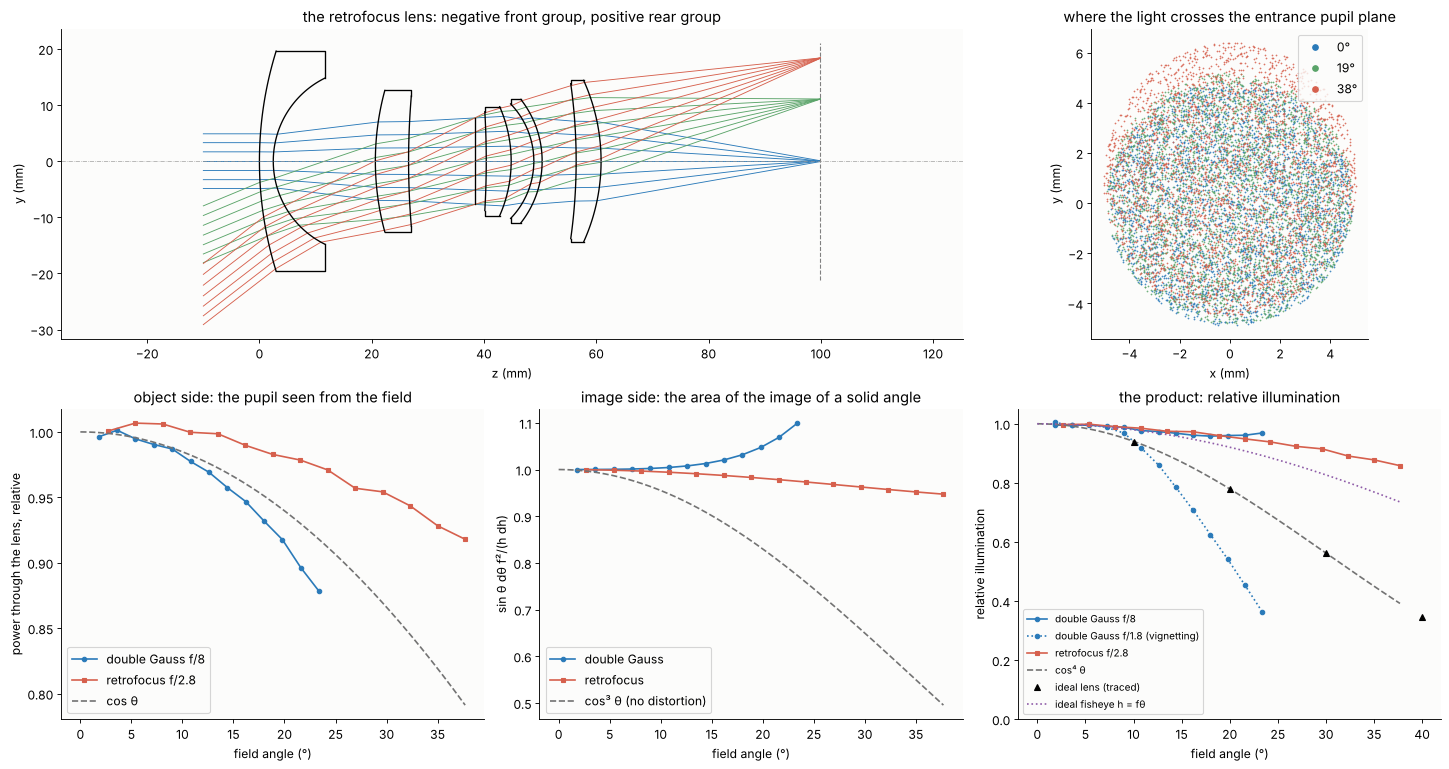

In [9]:
fig = plt.figure(figsize=(18, 9.5), layout="constrained")
gs = fig.add_gridspec(2, 3)
ax0 = fig.add_subplot(gs[0, :2])
rf.draw(ax0, fields=[0.0, 0.6*rf.max_field, rf.max_field], n_rays=7, colors=[BLUE, GREEN, RED])
ax0.set_aspect("equal")
ax0.set_xlabel("z (mm)")
ax0.set_ylabel("y (mm)")
ax0.set_title("the retrofocus lens: negative front group, positive rear group")
ax1 = fig.add_subplot(gs[0, 2])
for k, f in enumerate([0.0, 0.5*rf.max_field, rf.max_field]):
    fp = ph.point_footprint(rf, f, 20000, rng)
    ax1.plot(fp.pupil_x[::4], fp.pupil_y[::4], ".", ms=1, color=[BLUE, GREEN, RED][k],
             label="{:.0f}°".format(np.rad2deg(f)))
ax1.set_aspect("equal")
ax1.set_xlabel("x (mm)")
ax1.set_ylabel("y (mm)")
ax1.set_title("where the light crosses the entrance pupil plane")
ax1.legend(markerscale=10)
tt = np.linspace(0, rf.max_field, 200)
ax2 = fig.add_subplot(gs[1, 0])
ax2.plot(np.rad2deg(fields), P8, "o-", color=BLUE, ms=4, label="double Gauss f/8")
ax2.plot(np.rad2deg(fields_rf), P_rf, "s-", color=RED, ms=4, label="retrofocus f/2.8")
ax2.plot(np.rad2deg(tt), np.cos(tt), "--", color=GREY, label="cos θ")
ax2.set_xlabel("field angle (°)")
ax2.set_ylabel("power through the lens, relative")
ax2.set_title("object side: the pupil seen from the field")
ax2.legend()
ax3 = fig.add_subplot(gs[1, 1])
ax3.plot(np.rad2deg(fields), area8, "o-", color=BLUE, ms=4, label="double Gauss")
ax3.plot(np.rad2deg(fields_rf), area_rf, "s-", color=RED, ms=4, label="retrofocus")
ax3.plot(np.rad2deg(tt), np.cos(tt)**3, "--", color=GREY, label="cos³ θ (no distortion)")
ax3.set_xlabel("field angle (°)")
ax3.set_ylabel("sin θ dθ f²/(h dh)")
ax3.set_title("image side: the area of the image of a solid angle")
ax3.legend()
ax4 = fig.add_subplot(gs[1, 2])
ax4.plot(np.rad2deg(fields), RI8, "o-", color=BLUE, ms=4, label="double Gauss f/8")
ax4.plot(np.rad2deg(fields), RI18, "o:", color=BLUE, ms=4, label="double Gauss f/1.8 (vignetting)")
ax4.plot(np.rad2deg(fields_rf), RI_rf, "s-", color=RED, ms=4, label="retrofocus f/2.8")
ax4.plot(np.rad2deg(tt), np.cos(tt)**4, "--", color=GREY, label="cos⁴ θ")
ax4.plot(np.rad2deg(fields_id), RI_id, "^", color="k", label="ideal lens (traced)")
ax4.plot(np.rad2deg(tt), np.cos(tt)*np.sinc(tt/np.pi), ":", color=PURPLE,
         label="ideal fisheye h = fθ")
ax4.set_ylim(0, 1.05)
ax4.set_xlabel("field angle (°)")
ax4.set_ylabel("relative illumination")
ax4.set_title("the product: relative illumination")
ax4.legend(fontsize=9)
plt.show()

The panels show the two mechanisms one by one. Top right: from the edge
of the field the light crosses the paraxial entrance pupil plane in a
larger and shifted region than from the axis. This is the pupil
aberration of the negative front group, and it is what Slyusarev used
to beat $\cos^4$. Bottom: the object side factor of the retrofocus stays
above $\cos\theta$ at every field, while that of the double Gauss falls
below it. The image side factor is set by the distortion: $\cos^3\theta$
for $h = f\tan\theta$, much flatter for barrel distortion, which is also
why fisheye lenses ($h = f\theta$, dotted: $\cos\theta\,\sin\theta/\theta$
with a constant pupil) are so evenly lit. This design leans heavily on
its distortion, which was only held to a few percent at 75 % of the
field; commercial retrofocus lenses correct distortion better, keep the
pupil effect and then use vignetting to keep the front element small.
Their corners at full aperture are typically at 50 to 70 %, with
$\cos^4$ at 39 %. The ideal lens (triangles) confirms that the method
gives exactly $\cos^4$ when there is nothing to beat it with.

## 4. Point sources and extended sources

The camera equation is about extended objects. A star is a point: all of
its light that enters the aperture ends up in one small image, so what
counts is the power collected, $\propto D^2$, not the F-number. For an
extended object only $N$ counts. A telescope pointed at the Moon with an
eyepiece of magnification $M$ has the exit pupil $D/M$. The eye's pupil
($d$ = 7 mm at night) then limits the cone of light on the retina, and
the brightness theorem says the retinal irradiance is at most that of the
naked eye. It falls by $(D/Md)^2$ once the exit pupil gets smaller than
the eye's. The light from a star, though, all goes into one retinal spot
as long as the exit pupil is smaller than the eye's, $(D/d)^2$ more than
the naked eye collects.

A microscope works the other way round. The object is lit, and the
image on the camera (or the retina) has the irradiance
$\propto L\,\mathrm{NA}^2/M^2$ in transmitted light, since the cone in
image space is $\mathrm{NA}/M$. In epi-fluorescence the objective also
concentrates the excitation light onto the field, by
$\propto \mathrm{NA}^2$ of the condenser it acts as, and the image goes as
$\mathrm{NA}^4/M^2$.

In [10]:
# a 100 mm telescope and the eye at night (7 mm pupil)
D_tel, d_eye, T_tel = 100.0, 7.0, 0.9
M = np.linspace(1, 120, 400)
exit_pupil = D_tel/M
extended = T_tel*np.minimum(1.0, (exit_pupil/d_eye)**2)
star = T_tel*(np.minimum(exit_pupil, d_eye)*M/d_eye)**2
M_min = D_tel/d_eye
print("smallest magnification that fills the eye pupil: {:.1f}x (exit pupil 7 mm)".format(M_min))
print("star: {:.0f} times more light than the naked eye, {:.1f} magnitudes".format(
    T_tel*(D_tel/d_eye)**2, 2.5*np.log10(T_tel*(D_tel/d_eye)**2)))
# microscope objectives: image irradiance in transmitted light (NA/M)² and fluorescence NA⁴/M²
objectives = [("10x/0.25", 10, 0.25), ("20x/0.50", 20, 0.5), ("40x/0.65", 40, 0.65), ("40x/1.30 oil", 40, 1.3),
              ("60x/1.40 oil", 60, 1.4), ("100x/1.40 oil", 100, 1.4)]
print(" objective        (NA/M)² rel.   NA⁴/M² rel.")
ref = objectives[0]
for name, Mo, NA in objectives:
    print("{:15s}  {:8.3f}       {:8.2f}".format(name, (NA/Mo)**2/(ref[2]/ref[1])**2, NA**4/Mo**2/(ref[2]**4/ref[1]**2)))

smallest magnification that fills the eye pupil: 14.3x (exit pupil 7 mm)
star: 184 times more light than the naked eye, 5.7 magnitudes
 objective        (NA/M)² rel.   NA⁴/M² rel.
10x/0.25            1.000           1.00
20x/0.50            1.000           4.00
40x/0.65            0.422           2.86
40x/1.30 oil        1.690          45.70
60x/1.40 oil        0.871          27.32
100x/1.40 oil       0.314           9.83


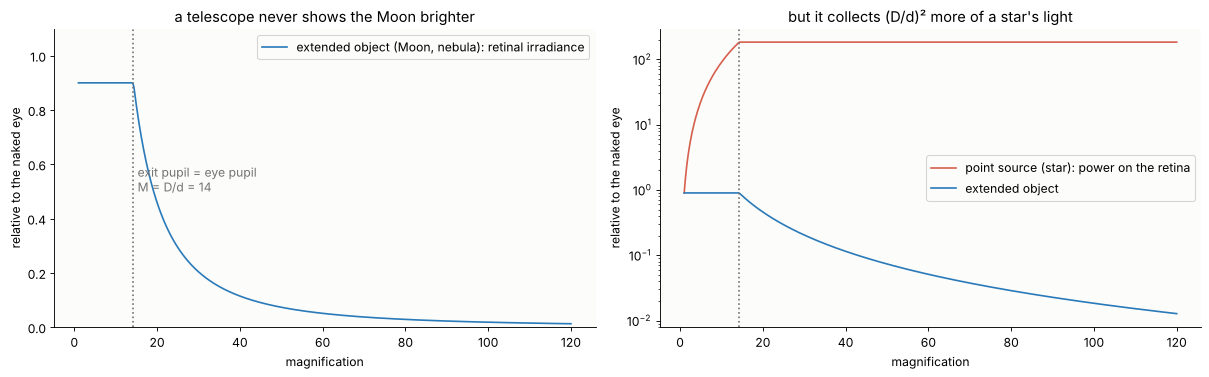

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
ax[0].plot(M, extended, color=BLUE, label="extended object (Moon, nebula): retinal irradiance")
ax[0].axvline(M_min, color=GREY, ls=":")
ax[0].text(M_min + 1, 0.5, "exit pupil = eye pupil\nM = D/d = {:.0f}".format(M_min), color=GREY)
ax[0].set_xlabel("magnification")
ax[0].set_ylabel("relative to the naked eye")
ax[0].set_title("a telescope never shows the Moon brighter")
ax[0].set_ylim(0, 1.1)
ax[0].legend(loc="upper right")
ax[1].semilogy(M, star, color=RED, label="point source (star): power on the retina")
ax[1].semilogy(M, extended, color=BLUE, label="extended object")
ax[1].axvline(M_min, color=GREY, ls=":")
ax[1].set_xlabel("magnification")
ax[1].set_ylabel("relative to the naked eye")
ax[1].set_title("but it collects (D/d)² more of a star's light")
ax[1].legend()
plt.show()

A 100 mm telescope (with $T$ = 0.9) collects 184 times the light of a
star that the naked eye does, 5.7 magnitudes, as long as its exit pupil
is at most 7 mm, i.e. above 14× magnification. The Moon, though, never
looks brighter than with the naked eye, and at 100× it is 50 times
fainter. This is why astronomers speak of "light grasp" for stars and of
the "exit pupil" for nebulae: no telescope shows a faint galaxy brighter,
only larger.

In the microscope table, the 40×/1.30 oil objective gives the brightest
fluorescence image, 46 times that of the 10×/0.25; the 100×/1.40 gives
only a fifth of that, because its larger magnification spreads the light
over a 6 times larger area. The rule "use the lowest magnification with
the highest NA" for fluorescence is the camera equation in a microscope.

## 5. From luminance to electrons

A reflected light meter measures the mean luminance $L$ of the scene and
sets the exposure by the ISO 2720 relation

$$\frac{N^2}{t} = \frac{L\,S}{K},\qquad K = 12.5\ \mathrm{cd\,s\,m^{-2}},$$

for the ISO speed $S$ (`rad.metered_exposure()`). The rule of thumb
"sunny 16" says: in bright sunlight, f/16 at $t = 1/S$. A scene of mean
reflectance 18 % (the "grey card"), lit by the illuminance $E$, has the
luminance $L = 0.18E/\pi$. With the Sun's 125 klx above the atmosphere
(notebook 105, radiometry and photometry), a simple clear sky model gives the illuminance on the
ground for the Sun at the elevation $h$: the direct beam, attenuated
along the air mass $1/\sin h$ (Meinel's formula) and projected onto the
ground, plus some diffuse skylight.

The camera equation then gives the exposure on the sensor. ISO 12232
writes it as $H = qLt/N^2$ with $q = 0.65$, which is $\pi/4$ times the
transmittance, $\cos^4$ and vignetting of a typical lens. For the metered
grey that is $H = qK/S$, and counting the photons per lux second of
daylight (notebook 105, radiometry and photometry, section 6), the number of electrons in a pixel
follows: here for a green pixel that gets 35 % of the photons (the rest
go to the red and blue pixels), with a quantum efficiency of 0.5.

In [12]:
# daylight: the Sun at the elevation h above the horizon, with a simple clear sky model
E_top = 125e3                  # lx, the 5772 K black body at 1 AU (notebook 105, radiometry and photometry)
elev = np.deg2rad(np.linspace(10, 90, 81))
air_mass = 1/np.sin(elev)
E_direct = E_top*0.8**(air_mass**0.678)*np.sin(elev)      # Meinel's attenuation, on a horizontal plane
E_sky = 0.12*E_top*np.sin(elev)**0.5                        # rough diffuse sky
E_ground = E_direct + E_sky
rho_grey = 0.18
L_scene = rho_grey*E_ground/np.pi
K = 12.5
for e_deg in (20, 40, 60):
    i = np.argmin(np.abs(np.rad2deg(elev) - e_deg))
    t = rad.metered_exposure(L_scene[i], 100, 16.0, K)
    print("Sun {:2d}° high: illuminance {:5.0f} klx, 18 % grey {:5.0f} cd/m², ISO 100 at f/16: 1/{:.0f} s, EV {:.1f}".format(
        e_deg, E_ground[i]/1e3, L_scene[i], 1/t, rad.exposure_value(16.0, t)))
# exposure at the sensor for the metered grey: H = q L t/N², with q = π T cos⁴ v/4 = 0.65 (ISO 12232)
q = 0.65
S_iso = np.array([100, 400, 1600, 6400, 25600])
H_grey = q*K/S_iso                                         # lx s
print("mid grey exposure at the sensor: H = q K/S = {:.3f} lx s at ISO 100".format(H_grey[0]))
# photons per lux second, for daylight (5772 K) in 400-700 nm (an IR cut filter)
lv = np.linspace(360, 830, 4701)
lp = np.linspace(400, 700, 3001)
bb_v = rad.planck_radiance(lv, 5772)
bb_p = rad.planck_radiance(lp, 5772)
photons_per_lxs = np.trapezoid(rad.photon_flux(bb_p, lp), lp)/rad.luminous_flux(lv, bb_v)
print("daylight: {:.2e} photons per m² per lx s (400-700 nm)".format(photons_per_lxs))
pitches = {"full frame, 6 µm": 6e-6, "APS-C, 4 µm": 4e-6, "phone, 1 µm": 1e-6}
qe_green, green_share = 0.5, 0.35
electrons = {}
for name, pitch in pitches.items():
    e = H_grey*photons_per_lxs*pitch**2*green_share*qe_green
    electrons[name] = e
    print("{:18s}: green pixel at mid grey: {:s} electrons, SNR {:s}".format(
        name, ", ".join("{:.0f}".format(v) for v in e), ", ".join("{:.0f}".format(v) for v in np.sqrt(e))))

Sun 20° high: illuminance    36 klx, 18 % grey  2046 cd/m², ISO 100 at f/16: 1/64 s, EV 14.0
Sun 40° high: illuminance    71 klx, 18 % grey  4096 cd/m², ISO 100 at f/16: 1/128 s, EV 15.0
Sun 60° high: illuminance    99 klx, 18 % grey  5650 cd/m², ISO 100 at f/16: 1/177 s, EV 15.5
mid grey exposure at the sensor: H = q K/S = 0.081 lx s at ISO 100
daylight: 1.09e+16 photons per m² per lx s (400-700 nm)
full frame, 6 µm  : green pixel at mid grey: 5602, 1400, 350, 88, 22 electrons, SNR 75, 37, 19, 9, 5
APS-C, 4 µm       : green pixel at mid grey: 2490, 622, 156, 39, 10 electrons, SNR 50, 25, 12, 6, 3
phone, 1 µm       : green pixel at mid grey: 156, 39, 10, 2, 1 electrons, SNR 12, 6, 3, 2, 1


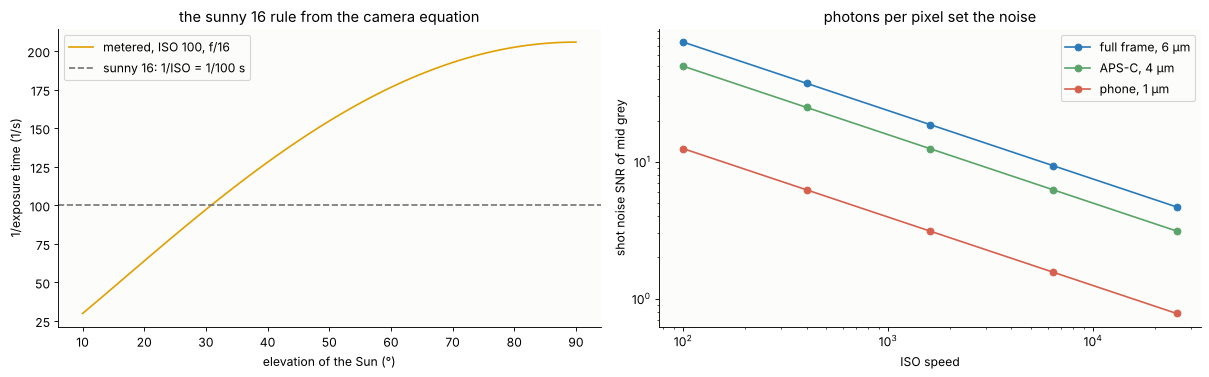

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
t_meter = rad.metered_exposure(L_scene, 100, 16.0, K)
ax[0].plot(np.rad2deg(elev), 1/t_meter, color=ORANGE, label="metered, ISO 100, f/16")
ax[0].axhline(100, color=GREY, ls="--", label="sunny 16: 1/ISO = 1/100 s")
ax[0].set_xlabel("elevation of the Sun (°)")
ax[0].set_ylabel("1/exposure time (1/s)")
ax[0].set_title("the sunny 16 rule from the camera equation")
ax[0].legend()
for (name, e), c in zip(electrons.items(), (BLUE, GREEN, RED)):
    ax[1].loglog(S_iso, np.sqrt(e), "o-", color=c, label=name)
ax[1].set_xlabel("ISO speed")
ax[1].set_ylabel("shot noise SNR of mid grey")
ax[1].set_title("photons per pixel set the noise")
ax[1].legend()
plt.show()

With the Sun 40° above the horizon the meter sets 1/128 s at f/16 and
ISO 100, EV 15, close to the 1/100 s of the rule. Higher sun gives a
little less exposure, lower sun more: sunny 16 is a rule for the middle
of the day. At the sensor the grey card is 0.081 lx s at ISO 100. Daylight
has $1.1\times10^{16}$ photons per m² and lx s in the visible, so a 4 µm
green pixel collects about 2500 electrons from mid grey, a shot noise SNR
of 50. Every doubling of the ISO speed halves the light and divides the
SNR by $\sqrt2$: at ISO 6400 the same pixel sees 39 electrons, SNR 6. A
1 µm phone pixel has a sixteenth of the area and is at SNR 12 already at
ISO 100, which is why phones average many frames. Read noise, dark
current and the photon response nonuniformity come on top of this, so
these numbers are an upper limit of the image quality.

## Summary

- **Camera equation:** $E' = \pi TL\sin^2\theta' = \pi TL/(4N_w^2)$ with
  the working F-number $N_w = N(1 + |m|/m_p)$. The traced double Gauss
  agrees at f/8 and to 1.3 % wide open (the sine condition at the rim).
  Close up, the pupil magnification matters: $(1 + |m|)$ alone is 11 %
  off at $m = -0.37$. Fresnel losses make the uncoated f/1.8 a T/2.4.
- **cos⁴ taken apart:** object side, the projected (and real) entrance
  pupil; image side, the area that the chief ray mapping gives a solid
  angle, $f^2\sin\theta\,d\theta/(h\,dh)$, which is $\cos^3\theta$ only
  without distortion (`ph.relative_illumination(image_side=True)`,
  checked against an ideal lens). Barrel distortion raises the corners;
  vignetting lowers them, and dominates in fast normal lenses.
- **Retrofocus:** the 28 mm f/2.8 lens (`ph.retrofocus()`) has a pupil
  magnification of 2.3; its entrance pupil grows towards the field (13 %
  above the projected pupil at 35°) and its barrel distortion flattens
  the image side factor, so the corner gets 0.88 instead of $\cos^4$ =
  0.45. Fisheyes go further: $\cos\theta\sin\theta/\theta$.
- **Point and extended sources:** a telescope gathers $(D/d)^2$ more
  light from a star but never shows the Moon brighter than the naked eye.
  Microscope images go as $\mathrm{NA}^2/M^2$ (transmitted) and
  $\mathrm{NA}^4/M^2$ (fluorescence).
- **Exposure:** the meter equation $N^2/t = LS/K$ with $K = 12.5$ and the
  sunlit grey card give EV 15, sunny 16. At the sensor, mid grey at
  ISO 100 is 0.081 lx s, about 2500 electrons in a 4 µm green pixel: the
  shot noise limit of an image is set by radiometry.

In [14]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 10 s


## References

- R. Kingslake, *Lens Design Fundamentals*, Academic Press (1978),
  chapter 1 on the image illumination, and *A History of the Photographic
  Lens*, Academic Press (1989), chapter 10 on retrofocus lenses.
- M. Reiss, "The cos⁴ law of illumination", J. Opt. Soc. Am. 35, 283–288
  (1945), and "Notes on the cos⁴ law of illumination", J. Opt. Soc. Am. 38,
  980–986 (1948).
- G. G. Slyusarev, "The possibility of increasing the illumination at the
  edge of the field of a wide angle lens beyond the cos⁴ law", Dokl. Akad.
  Nauk SSSR 31 (1941).
- W. J. Smith, *Modern Optical Engineering*, 4th ed., McGraw-Hill (2008),
  chapter 9 (radiometry and photometry of images).
- R. W. Boyd, *Radiometry and the Detection of Optical Radiation*, Wiley
  (1983).
- ISO 2720:1974, *General purpose photographic exposure meters*, and
  ISO 12232:2019, *Photography — Digital still cameras — Determination of
  exposure index, ISO speed ratings, standard output sensitivity and
  recommended exposure index*.
- A. B. Meinel and M. P. Meinel, *Applied Solar Energy*, Addison-Wesley
  (1976), on the attenuation of sunlight with the air mass.
- J. B. Pawley (ed.), *Handbook of Biological Confocal Microscopy*, 3rd
  ed., Springer (2006), on the brightness of fluorescence images.